In [ ]:
import torch

print("PyTorch Version:", torch.__version__)

if torch.cuda.is_available():
    print("GPU Available:", torch.cuda.get_device_name(0))
else:
    print("GPU Not Available")

PyTorch Version: 2.14.1+cu130
GPU Available: Tesla T4


In [ ]:
!pip install onnx onnxscript

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 40.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 27.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [onnxscript]


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import onnx
import os

print("All libraries imported successfully!")
print("PyTorch:", torch.__version__)
print("ONNX:", onnx.__version__)

All libraries imported successfully!
PyTorch: 2.14.1+cu130
ONNX: 1.23.2


In [ ]:
import torch
import torch.nn as nn

class DigitClassifier(nn.Module):

    def __init__(self):
        super(DigitClassifier, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)

model = DigitClassifier()

model = model.to('cuda')

print(model)

DigitClassifier(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [ ]:
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = torchvision.datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Dataset loaded successfully!")

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 506kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.55MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.0MB/s]

Training images: 60000
Testing images: 10000
Dataset loaded successfully!


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function and optimizer initialized successfully!")

Loss function and optimizer initialized successfully!


In [ ]:
epochs = 5

for epoch in range(epochs):

    model.train()
    running_loss = 0.0

    for images, labels in train_loader:

        images = images.view(-1, 784).to('cuda')
        labels = labels.to('cuda')

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Loss: {running_loss/len(train_loader):.4f}"
    )

print("Model training completed!")

Epoch [1/5], Loss: 0.0828
Epoch [2/5], Loss: 0.0756
Epoch [3/5], Loss: 0.0667
Epoch [4/5], Loss: 0.0601
Epoch [5/5], Loss: 0.0558
Model training completed!


In [ ]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.view(-1, 784).to('cuda')
        labels = labels.to('cuda')

        outputs = model(images)

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 96.89%


In [ ]:
torch.save(
    model.state_dict(),
    "digit_classifier.pth"
)

print("Model checkpoint saved successfully!")

Model checkpoint saved successfully!


In [ ]:
import os

print("File exists:", os.path.exists("digit_classifier.pth"))
print("File size:", os.path.getsize("digit_classifier.pth"), "bytes")

File exists: True
File size: 440769 bytes


In [ ]:
model.eval()

dummy_input = torch.randn(1, 784).to('cuda')

torch.onnx.export(
    model,
    dummy_input,
    "digit_classifier.onnx",
    input_names=["input"],
    output_names=["output"],
    dynamo=False,
    opset_version=17
)

print("Model exported to ONNX successfully!")

Model exported to ONNX successfully!


/tmp/ipykernel_342/382450031.py:5: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


In [ ]:
import onnx

onnx_model = onnx.load("digit_classifier.onnx")

onnx.checker.check_model(onnx_model)

print("ONNX model loaded successfully!")
print("ONNX graph validated successfully!")

ONNX model loaded successfully!
ONNX graph validated successfully!


In [ ]:
!pip install tensorrt-cu13

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 42.3 MB/s  0:00:00
  Created wheel for tensorrt-cu13: filename=tensorrt_cu13-11.5.0.63-py3-none-any.whl size=23057 sha256=d4f3fdd9854e50bd60b35dd0595614fa199f2a81b804e2b5aee8c5142502902f
  Stored in directory: /root/.cache/pip/wheels/89/4d/e8/f493972a5dc2a1733d7b9f43abd67b965e2356ac4c8657e0fc
  Created wheel for tensorrt_cu13_libs: filename=tensorrt_cu13_libs-11.5.0.63-py3-none-manylinux_2_28_x86_64.whl size=3836415489 sha256=56f4b6764cf86ed22202234b7a89d22a6b817493ab76f0c9d1a8d55d8497efdc
  Stored in directory: /root/.cache/pip/wheels/5e/a8/60/f4680682020406254d287677e3400aaad753f00cee614ceace
Successfully built tensorrt-cu13 tensorrt_cu13_libs
   ━━━━━━━━━━━━━━━━━━

In [ ]:
import tensorrt as trt

print("TensorRT Version:", trt.__version__)
print("TensorRT imported successfully!")

TensorRT Version: 11.5.0.63
TensorRT imported successfully!


In [ ]:
import tensorrt as trt

print("TensorRT Version:", trt.__version__)
print("TensorRT imported successfully!")

TensorRT Version: 11.5.0.63
TensorRT imported successfully!


In [ ]:
import torch

print("GPU:", torch.cuda.get_device_name(0))
print("CUDA Version:", torch.version.cuda)
print("GPU Available:", torch.cuda.is_available())

GPU: Tesla T4
CUDA Version: 13.0
GPU Available: True


In [ ]:
import tensorrt as trt

# Create TensorRT logger and builder
logger = trt.Logger(trt.Logger.WARNING)
builder = trt.Builder(logger)

# Create network and configuration
network = builder.create_network(0)
config = builder.create_builder_config()

# Set workspace memory limit (1 GB)
config.set_memory_pool_limit(
    trt.MemoryPoolType.WORKSPACE,
    1 << 30
)

# Create ONNX parser
parser = trt.OnnxParser(network, logger)

# Load ONNX model
with open("digit_classifier.onnx", "rb") as f:
    success = parser.parse(f.read())

if not success:
    for i in range(parser.num_errors):
        print(parser.get_error(i))
    raise RuntimeError("ONNX parsing failed!")

print("ONNX model parsed successfully!")

# Build TensorRT engine
serialized_engine = builder.build_serialized_network(
    network, config
)

if serialized_engine is None:
    raise RuntimeError("TensorRT engine generation failed!")

# Save engine
with open("digit_classifier.engine", "wb") as f:
    f.write(serialized_engine)

print("TensorRT engine generated successfully!")

ONNX model parsed successfully!
TensorRT engine generated successfully!


In [ ]:
import os

engine_path = "digit_classifier.engine"

print("Engine file exists:", os.path.exists(engine_path))
print("Engine file size:", os.path.getsize(engine_path), "bytes")

Engine file exists: True
Engine file size: 462508 bytes


In [ ]:
import os

files = [
    "digit_classifier.pth",
    "digit_classifier.onnx",
    "digit_classifier.engine"
]

print("MODEL ARTEFACT LIFECYCLE")
print("------------------------")

for file in files:
    if os.path.exists(file):
        size = os.path.getsize(file)
        print(f"{file} : Generated ({size} bytes)")
    else:
        print(f"{file} : Not found")

MODEL ARTEFACT LIFECYCLE
------------------------
digit_classifier.pth : Generated (440769 bytes)
digit_classifier.onnx : Generated (438510 bytes)
digit_classifier.engine : Generated (462508 bytes)


In [ ]:
from google.colab import files

files.download("digit_classifier.pth")
files.download("digit_classifier.onnx")
files.download("digit_classifier.engine")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("MODEL ARTEFACT LIFECYCLE REPORT")
print("--------------------------------")

print("1. Model Architecture: DigitClassifier")
print("2. Training Dataset: MNIST")
print("3. Training Epochs: 5")
print("4. Test Accuracy: 96.89%")
print("5. Checkpoint Format: .pth")
print("6. ONNX Graph Format: .onnx")
print("7. TensorRT Engine Format: .engine")

print("--------------------------------")
print("Model lifecycle verification completed!")

MODEL ARTEFACT LIFECYCLE REPORT
--------------------------------
1. Model Architecture: DigitClassifier
2. Training Dataset: MNIST
3. Training Epochs: 5
4. Test Accuracy: 96.89%
5. Checkpoint Format: .pth
6. ONNX Graph Format: .onnx
7. TensorRT Engine Format: .engine
--------------------------------
Model lifecycle verification completed!


In [ ]:
loaded_model = DigitClassifier().to('cuda')

loaded_model.load_state_dict(
    torch.load(
        "digit_classifier.pth",
        map_location='cuda',
        weights_only=True
    )
)

loaded_model.eval()

print("Trained checkpoint loaded successfully!")

Trained checkpoint loaded successfully!


In [ ]:
images, labels = next(iter(test_loader))

images = images.view(-1, 784).to('cuda')

with torch.no_grad():
    outputs = loaded_model(images)
    predictions = outputs.argmax(dim=1)

print("Actual labels:    ", labels[:10].tolist())
print("Predicted labels: ", predictions[:10].cpu().tolist())

Actual labels:     [7, 2, 1, 0, 4, 1, 4, 9, 5, 9]
Predicted labels:  [7, 2, 1, 0, 4, 1, 4, 9, 5, 9]


In [ ]:
import os

print("===== MODEL ARTEFACT LIFECYCLE =====")

print("\nModel Architecture:")
print(model)

print("\nGenerated Files:")

for file in [
    "digit_classifier.pth",
    "digit_classifier.onnx",
    "digit_classifier.engine"
]:
    if os.path.exists(file):
        print(file, "- Available")
    else:
        print(file, "- Not Generated")

print("\nTest Accuracy: 96.89%")
print("\nPractical execution completed!")

===== MODEL ARTEFACT LIFECYCLE =====

Model Architecture:
DigitClassifier(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)

Generated Files:
digit_classifier.pth - Available
digit_classifier.onnx - Available
digit_classifier.engine - Available

Test Accuracy: 96.89%

Practical execution completed!


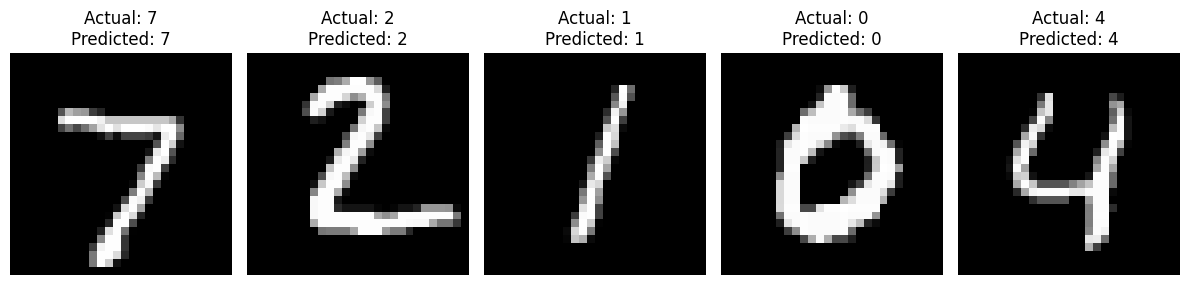

In [ ]:
import matplotlib.pyplot as plt

# Get one batch of test images
images, labels = next(iter(test_loader))

# Select 5 images
images = images[:5]
labels = labels[:5]

# Predict using the trained model
model.eval()

with torch.no_grad():
    inputs = images.view(-1, 784).to('cuda')
    outputs = model(inputs)
    predictions = outputs.argmax(dim=1).cpu()

# Display predictions
plt.figure(figsize=(12, 4))

for i in range(5):
    plt.subplot(1, 5, i + 1)

    plt.imshow(images[i].squeeze(), cmap='gray')
    plt.title(
        f"Actual: {labels[i].item()}\nPredicted: {predictions[i].item()}"
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import os

from IPython.display import display, Markdown

display(Markdown("# Model Artefact Lifecycle"))

for filename in [
    "digit_classifier.pth",
    "digit_classifier.onnx",
    "digit_classifier.engine"
]:
    if os.path.exists(filename):
        print("✅", filename, "-", os.path.getsize(filename), "bytes")
    else:
        print("❌", filename, "- Not generated")

# Model Artefact Lifecycle

✅ digit_classifier.pth - 440769 bytes
✅ digit_classifier.onnx - 438510 bytes
✅ digit_classifier.engine - 462508 bytes


In [ ]:
import matplotlib.pyplot as plt

epochs = 5
loss_values = []

for epoch in range(epochs):

    model.train()
    running_loss = 0.0

    for images, labels in train_loader:

        images = images.view(-1, 784).to('cuda')
        labels = labels.to('cuda')

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    loss_values.append(epoch_loss)

    print(f"Epoch [{epoch+1}/5], Loss: {epoch_loss:.4f}")

print("Training completed!")

Epoch [1/5], Loss: 0.0500
Epoch [2/5], Loss: 0.0467
Epoch [3/5], Loss: 0.0443
Epoch [4/5], Loss: 0.0413
Epoch [5/5], Loss: 0.0375
Training completed!


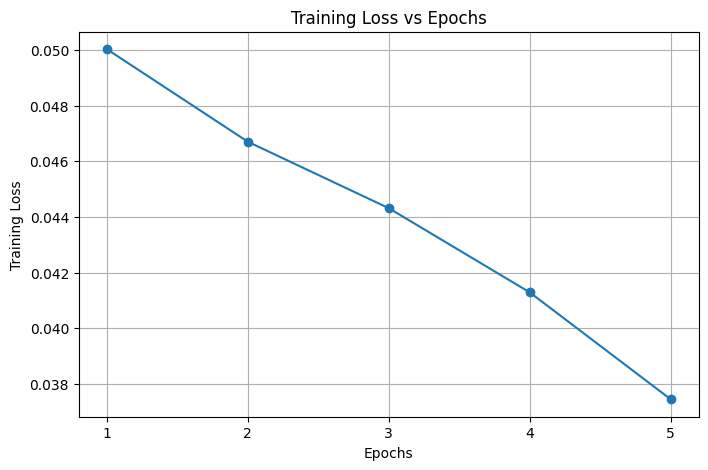

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, 6), loss_values, marker='o')

plt.title("Training Loss vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Training Loss")

plt.xticks(range(1, 6))
plt.grid(True)

plt.show()

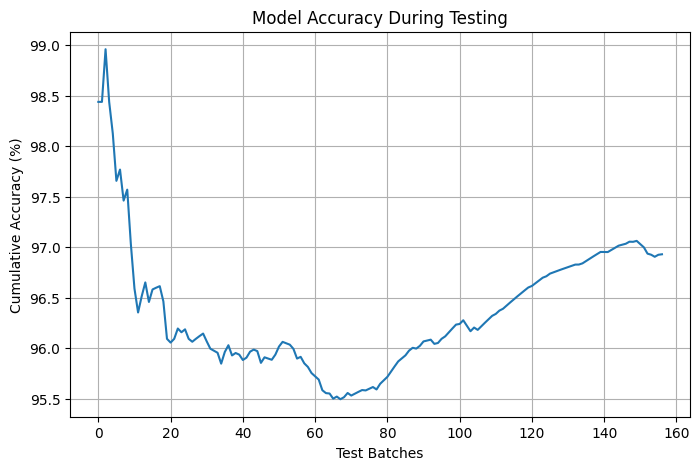

Final Test Accuracy: 96.93%


In [ ]:
model.eval()

correct = 0
total = 0
accuracy_values = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.view(-1, 784).to('cuda')
        labels = labels.to('cuda')

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        accuracy_values.append(
            100 * correct / total
        )

final_accuracy = 100 * correct / total

plt.figure(figsize=(8, 5))

plt.plot(accuracy_values)

plt.title("Model Accuracy During Testing")
plt.xlabel("Test Batches")
plt.ylabel("Cumulative Accuracy (%)")

plt.grid(True)
plt.show()

print(f"Final Test Accuracy: {final_accuracy:.2f}%")